# LAB1 - Bài 10 (Trang 30): tb_tracking.xlsx - tiền xử lý dữ liệu cảm biến

**Họ tên:** Đinh Công Vinh Quang  
**MSSV:** 6451071061

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

HO_TEN, MSSV = "Đinh Công Vinh Quang", "6451071061"
print(f"{HO_TEN} - {MSSV}")

Đinh Công Vinh Quang - 6451071061


In [2]:
# a) đọc dữ liệu (file không có tiêu đề) và thêm tiêu đề cột theo thứ tự
cols = ["id", "device_id", "co_level", "humidity", "temperature", "time"]
df = pd.read_excel("tb_tracking.xlsx", header=None, names=cols)
print("Kích thước ban đầu:", df.shape)
df.head()

Kích thước ban đầu: (33340, 6)


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01


In [3]:
# file có 4 dòng cuối không phải dữ liệu đo (1 dòng trống + 3 dòng thống kê min/max/mean) -> loại bỏ
df.tail(5)

,id,device_id,co_level,humidity,temperature,time
33335,33336.0,0.000000,31.500000,62.000000,2.004240e+06,2018-01-17 15:46:34.000
33336,NaN,NaN,NaN,NaN,NaN,NaT
33337,1.0,-1.000000,0.000000,0.000000,0.000000e+00,2016-12-20 12:52:29.000
33338,33336.0,99005.000000,4030.000000,11030.000000,5.340310e+06,2018-01-17 15:46:34.000
33339,16668.5,97931.172516,181.704089,2127.562065,1.384405e+05,2017-03-15 06:51:12.688


In [4]:
end = df["time"].isna().idxmax()          # vị trí dòng trống đầu tiên
df = df.loc[:end - 1].copy()
df["time"] = pd.to_datetime(df["time"])
print("Số dòng dữ liệu đo thật sự:", len(df))

Số dòng dữ liệu đo thật sự: 33336


In [5]:
# b) chỉ giữ dữ liệu từ ngày 03/01/2018 (ngày 3 tháng 1 năm 2018) trở đi
print("Trước khi lọc:", len(df))
df = df[df["time"] >= "2018-01-03"].copy()
print("Sau khi lọc :", len(df), "| từ", df["time"].min(), "đến", df["time"].max())
df.head()

Trước khi lọc: 33336
Sau khi lọc : 1917 | từ 2018-01-03 13:11:07 đến 2018-01-17 15:46:34


,id,device_id,co_level,humidity,temperature,time
31419,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
31420,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
31421,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
31422,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
31423,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17


In [6]:
# c) thời điểm đo trong ngày tính theo phút: minutes = giờ * 60 + phút
df["minutes"] = df["time"].dt.hour * 60 + df["time"].dt.minute
df[["time", "minutes"]].head(8)

,time,minutes
31419,2018-01-03 13:11:07,791
31420,2018-01-03 13:15:10,795
31421,2018-01-03 13:17:30,797
31422,2018-01-03 13:19:21,799
31423,2018-01-03 13:24:17,804
31424,2018-01-03 13:29:13,809
31425,2018-01-03 13:34:10,814
31426,2018-01-03 14:05:34,845


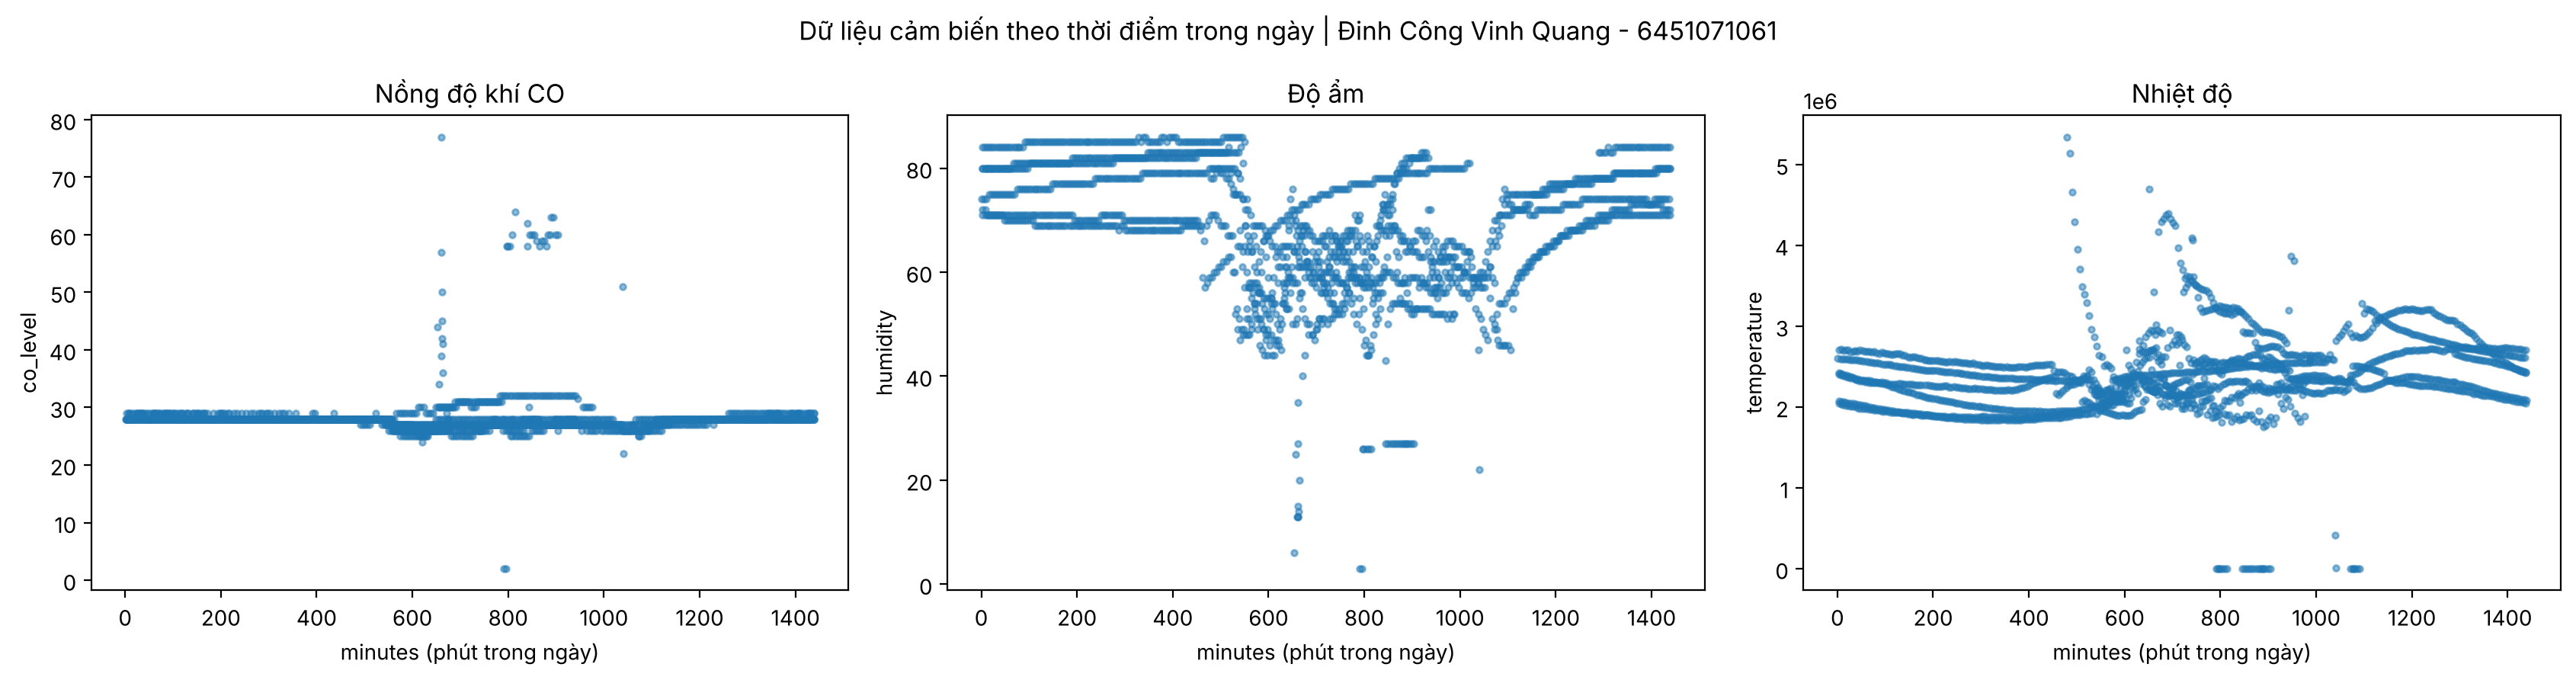

In [7]:
# d) đồ thị phân tán: CO, độ ẩm, nhiệt độ theo minutes
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c, name in zip(axes, ["co_level", "humidity", "temperature"], ["Nồng độ khí CO", "Độ ẩm", "Nhiệt độ"]):
    ax.scatter(df["minutes"], df[c], s=8, alpha=0.5)
    ax.set_xlabel("minutes (phút trong ngày)"); ax.set_ylabel(c); ax.set_title(name)
fig.suptitle(f"Dữ liệu cảm biến theo thời điểm trong ngày | {HO_TEN} - {MSSV}")
plt.tight_layout(); plt.show()